# Inversión clásica: baseline físico

**Equipo 39 · Proyecto Integrador MNA**

La inversión clásica estima el módulo de Young y el esfuerzo axial ajustando un modelo físico a las mediciones. En cada paso se resuelve el problema de valores propios de la viga; el ajuste minimiza residuales de frecuencias y formas modales ponderados por su incertidumbre. Es determinista, interpretable y adecuado para este conjunto pequeño de observaciones.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src' / 'pinn_mems').is_dir())
sys.path.insert(0, str(RAIZ / 'src'))
from pinn_mems.eigensolver import Soporte, Viga, resolver_modos
from pinn_mems.inversa.clasica import ajustar, correr_clasico
from pinn_mems.matriz import Corrida, configs_reservadas, frecuencias_reservadas, generar_corrida

## Ajuste y verificación en M0

El parámetro de ajuste es $\theta=E/E_{ref}$. Se inicia en $\theta_0=0.8$. La forma de cada modo tiene amplitud arbitraria; se elimina esa amplitud por mínimos cuadrados antes de comparar perfiles. M0 comprueba la recuperación usando una malla de inversión más gruesa que la de generación.

In [2]:
r_m0 = correr_clasico(Corrida('m0', 15, 3, 0), 3, sin_ruido=True)
err_m0 = r_m0.errores_relativos(r_m0.extra['verdaderos'])
print(f"E estimado: {r_m0.parametros['E']/1e9:.5f} GPa; error: {100*err_m0['E']:.4f}%")
print(f"sigma0 estimado: {r_m0.parametros['sigma0']/1e6:.5f} MPa; error: {100*err_m0['sigma0']:.4f}%")
print(f"Llamadas al eigensolver: {r_m0.n_resoluciones}; chi-cuadrado reducido: {r_m0.residuales['chi2_reducido']:.3g}")

E estimado: 70.00000 GPa; error: -0.0000%
sigma0 estimado: -5.00000 MPa; error: -0.0000%
Llamadas al eigensolver: 96; chi-cuadrado reducido: 5.76e-10


La incertidumbre local se aproxima con $(J^T J)^{-1}\chi^2_{red}$, donde $J$ es el Jacobiano de los residuales ponderados. Cambiar el punto inicial permite comprobar que el resultado no depende de una elección favorable.

In [3]:
inicio = []
for theta0 in (0.5, 0.8, 1.5):
    rr = ajustar(generar_corrida(Corrida('m0', 15, 3, 0)), 3, theta0=theta0, sin_ruido=True)
    inicio.append((theta0, rr.parametros['E']/1e9, rr.parametros['sigma0']/1e6))
for theta0, E_GPa, sigma_MPa in inicio:
    print(f'theta0={theta0:.1f}: E={E_GPa:.5f} GPa, sigma0={sigma_MPa:.5f} MPa')

theta0=0.5: E=70.00000 GPa, sigma0=-5.00000 MPa
theta0=0.8: E=70.00000 GPa, sigma0=-5.00000 MPa
theta0=1.5: E=70.00000 GPa, sigma0=-5.00000 MPa


## Qué observaciones informan el ajuste

El Jacobiano permite una selección *embedded*: cada fila representa una frecuencia o una ordenada de forma modal. La suma de cuadrados de cada fila mide su contribución local a la información del ajuste. Se muestra el grupo M1 s3 con tres estructuras y tres modos.

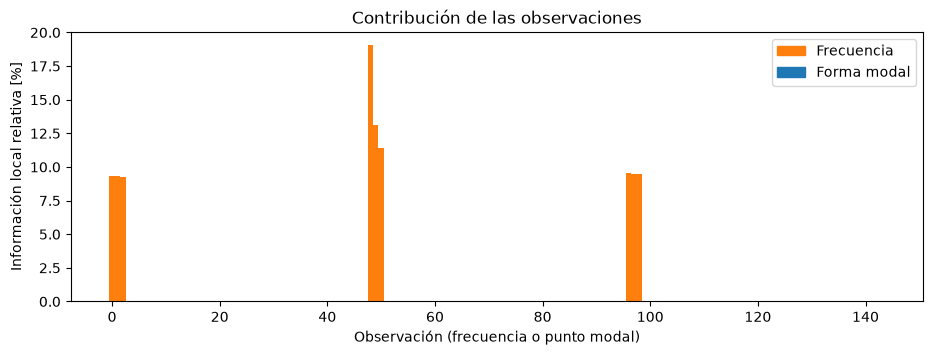

In [4]:
r_info = correr_clasico(Corrida('m1_s3', 15, 3, 0), 3, sin_ruido=True)
J = np.asarray(r_info.extra['jacobiano'])
info = 100 * np.sum(J**2, axis=1) / np.sum(J**2)
labels = r_info.extra['observaciones']
fig, ax = plt.subplots(figsize=(11, 3.5))
colors = ['tab:orange' if x['tipo'] == 'frecuencia' else 'tab:blue' for x in labels]
ax.bar(np.arange(len(info)), info, color=colors, width=1)
ax.set(xlabel='Observación (frecuencia o punto modal)', ylabel='Información local relativa [%]', title='Contribución de las observaciones')
ax.legend(handles=[plt.Rectangle((0,0),1,1,color='tab:orange',label='Frecuencia'), plt.Rectangle((0,0),1,1,color='tab:blue',label='Forma modal')])
plt.show()

La ablación *wrapper* retira observaciones y mide el cambio del error en $E$. Se varía el número de puntos y el de modos, con diez semillas por condición. La frecuencia determina la escala de $E$; las formas ayudan sobre todo a distinguir parámetros correlacionados.

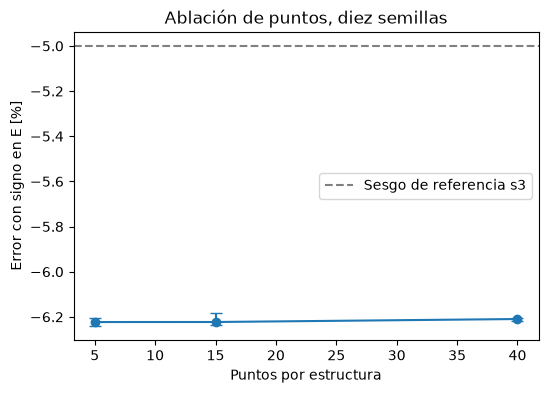

{1: (-6.1745174793003015, -6.191608029536393, -6.162606063198059), 3: (-6.2228198256562735, -6.235036327379293, -6.183227430901205)}


In [5]:
por_N = {}
for N in (5, 15, 40):
    errores = []
    for semilla in range(10):
        rr = correr_clasico(Corrida('m1_s3', N, 3, semilla), 3)
        errores.append(100 * rr.errores_relativos(rr.extra['verdaderos'])['E'])
    por_N[N] = np.asarray(errores)
fig, ax = plt.subplots(figsize=(6, 4))
med = [np.median(por_N[N]) for N in por_N]
q1 = [np.percentile(por_N[N], 25) for N in por_N]
q3 = [np.percentile(por_N[N], 75) for N in por_N]
ax.errorbar(list(por_N), med, yerr=[np.array(med)-q1, np.array(q3)-med], marker='o', capsize=4)
ax.axhline(-5, color='gray', linestyle='--', label='Sesgo de referencia s3')
ax.set(xlabel='Puntos por estructura', ylabel='Error con signo en E [%]', title='Ablación de puntos, diez semillas'); ax.legend(); plt.show()

por_modos = {}
for n_modos in (1, 3):
    por_modos[n_modos] = []
    for semilla in range(10):
        rr = correr_clasico(Corrida('m1_s3', 15, 3, semilla), n_modos)
        por_modos[n_modos].append(100 * rr.errores_relativos(rr.extra['verdaderos'])['E'])
print({k: (float(np.median(v)), float(np.percentile(v,25)), float(np.percentile(v,75))) for k,v in por_modos.items()})

## Identificabilidad: superficies de desajuste

Las mallas usan mediciones limpias y el mismo residual del ajuste. Una biempotrada sola deja un valle entre $E$ y $\sigma_0$; sumar el voladizo localiza el mínimo. Para el anclaje flexible, un modo deja $\kappa_\theta$ débilmente determinado y tres modos aportan más información.

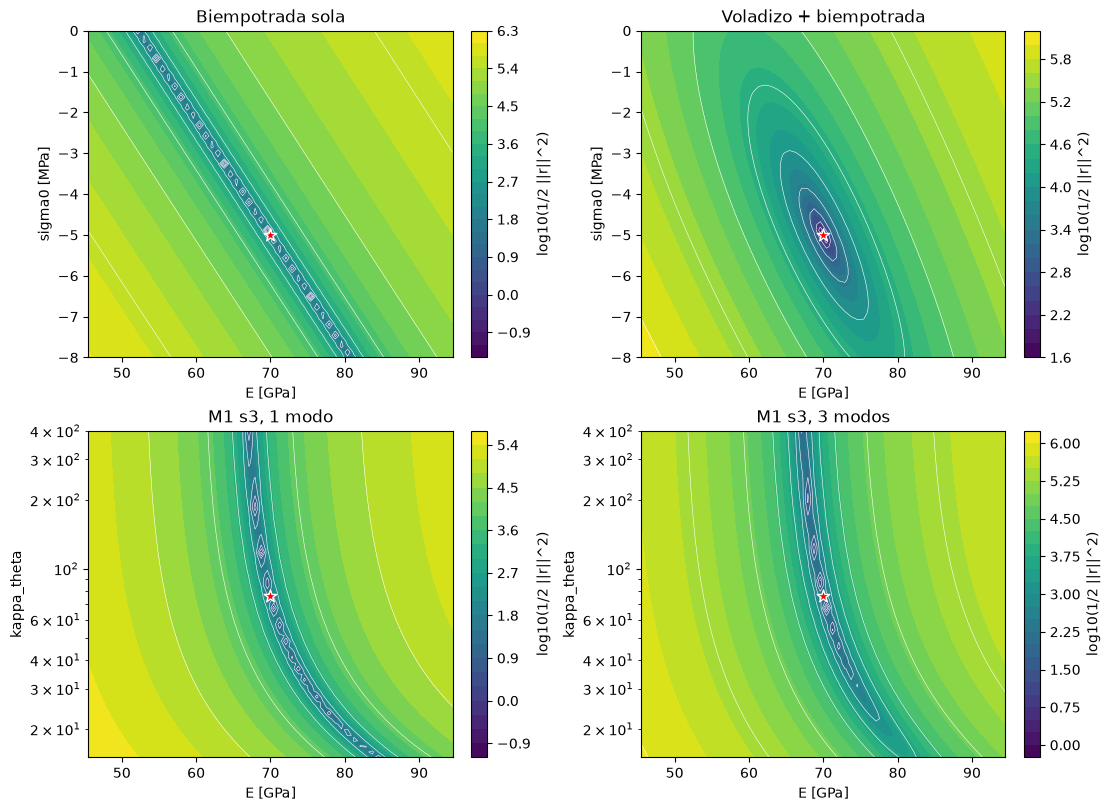

In [6]:
carpeta = RAIZ / 'resultados' / 'superficies'
archivos = [('t14_clasico_esigma_biempotrada.npz','Biempotrada sola'), ('t14_clasico_esigma_voladizo_biempotrada.npz','Voladizo + biempotrada'), ('t14_clasico_ekappa_s3_m1.npz','M1 s3, 1 modo'), ('t14_clasico_ekappa_s3_m3.npz','M1 s3, 3 modos')]
fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
for ax, (archivo, titulo) in zip(axes.flat, archivos):
    d = np.load(carpeta / archivo); E = d['theta'] * 70.0
    if 'sigma0_MPa' in d: y=d['sigma0_MPa']; ylabel='sigma0 [MPa]'; estrella=(70.0,-5.0)
    else: y=d['kappa_theta']; ylabel='kappa_theta'; estrella=(70.0,76.1171); ax.set_yscale('log')
    z=np.log10(np.maximum(d['costo'],1e-14)); cs=ax.contourf(E,y,z,levels=24,cmap='viridis')
    ax.contour(E,y,z,levels=10,colors='white',linewidths=0.4); ax.scatter(*estrella,marker='*',color='red',edgecolor='white',s=90)
    ax.set(title=titulo,xlabel='E [GPa]',ylabel=ylabel); fig.colorbar(cs,ax=ax,label='log10(1/2 ||r||^2)')
plt.show()

## Modos y longitudes retenidos

Un ajuste con el primer modo debe predecir los modos que no entraron en el objetivo. También se evalúan las longitudes de 248 y 348 micrómetros, reservadas durante el ajuste. La comparación entre M0 y M1 muestra si el ajuste se generaliza cuando el anclaje es flexible.

In [7]:
for caso in ('m0','m1_s3'):
    corrida=Corrida(caso,15,1,0); conjunto=generar_corrida(corrida)['voladizo']; rr=correr_clasico(corrida,1); p=conjunto.params
    v=Viga(E=rr.parametros['E'],L=float(p['L']),b=float(p['b']),h=float(p['h']),rho=float(p['rho']))
    pred=resolver_modos(v,'voladizo',n_modos=3,n_elem=100).omega
    print(caso,'errores relativos por modo [%]:',np.round(100*(pred/conjunto.omega_limpia-1),3))

m0 errores relativos por modo [%]: [-0.009 -0.009 -0.009]
m1_s3 errores relativos por modo [%]: [-0.009 -0.118 -0.21 ]


In [8]:
reservadas={(x['caso'],x['L_um']):x for x in frecuencias_reservadas()}
for caso in ('m0','m1_s3'):
    rr=correr_clasico(Corrida(caso,15,1,0),1); errores=[]
    for L_um,cfg in configs_reservadas(caso).items():
        p=cfg['params']; v=Viga(E=rr.parametros['E'],L=float(p['L']),b=float(p['b']),h=float(p['h']),rho=float(p['rho']))
        pred=resolver_modos(v,'voladizo',n_modos=1,n_elem=100).omega[0]; verdad=reservadas[(caso,L_um)]['omega1_rad_s']
        errores.append(100*(pred/verdad-1))
    print(caso,'error en frecuencias retenidas [%]:',np.round(errores,3))

m0 error en frecuencias retenidas [%]: [-0.009 -0.009]
m1_s3 error en frecuencias retenidas [%]: [ 0.514 -0.355]


## Diagnóstico de subajuste

El chi-cuadrado reducido se interpreta frente al ruido conocido: cerca de uno es compatible con el nivel de ruido; mucho mayor indica variación sin explicar. Un patrón espacial del residual en M1 es subajuste por error de modelo, no falta de capacidad del optimizador. En M0, los residuos deberían parecer ruido.

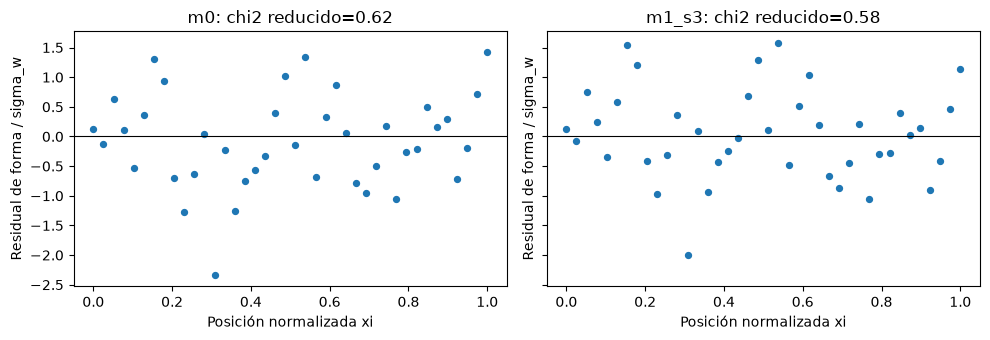

In [9]:
fig, axes=plt.subplots(1,2,figsize=(10,3.5),sharey=True)
for ax,caso in zip(axes,('m0','m1_s3')):
    rr=correr_clasico(Corrida(caso,40,1,0),1); labels=rr.extra['observaciones']; r=np.asarray(rr.extra['residuales_vector'])
    formas=[(x['xi'],v) for x,v in zip(labels,r) if x['tipo']=='forma' and x['modo']==1]
    ax.axhline(0,color='black',linewidth=0.8); ax.scatter([x for x,_ in formas],[y for _,y in formas],s=18)
    ax.set(title=f"{caso}: chi2 reducido={rr.residuales['chi2_reducido']:.2g}",xlabel='Posición normalizada xi',ylabel='Residual de forma / sigma_w')
plt.tight_layout(); plt.show()

## Conclusión

El baseline clásico resuelve el problema directo en cada iteración y recupera los parámetros de control cuando los datos provienen de M0. El Jacobiano y la ablación muestran qué mediciones sostienen cada estimación; las superficies muestran qué combinaciones son identificables. En M1, un residual con patrón cerca del anclaje y el error en mediciones retenidas señalan el límite de L0: optimizar mejor no corrige una física que supone un empotramiento ideal.